# Tópico 8 - Aliasing (Falseamento Espectral)

## Visão Geral e Objetivos
Neste notebook, investigamos experimentalmente o fenômeno do **Aliasing (Falseamento Espectral)** no processamento digital de sinais. Os principais objetivos são:
1. **Violação do Critério de Nyquist**: Amostrar um sinal senoidal de frequência $f_0 = 70\text{ Hz}$ com uma taxa de amostragem de $f_s = 100\text{ Hz}$, ultrapassando o limite de Nyquist ($f_N = 50\text{ Hz}$).
2. **Identificação da Frequência Aparente**: Demonstrar no tempo e na frequência que as amostras discretas obtidas tornam-se indistinguíveis de uma senoide de frequência aparente $f_{alias} = |70 - 100| = 30\text{ Hz}$.
3. **Formulação Matemática**: Explicar a dobra espectral em torno do limite de Nyquist $f_N = f_s / 2$.
4. **Exportação de Figuras**: Salvar os gráficos gerados diretamente no diretório local de simulação.

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt

# Garantir a criação do diretório local para exportação das imagens
os.makedirs(".", exist_ok=True)

## 1. Geração do Sinal Subamostrado no Domínio do Tempo

Consideramos um sinal senoidal original de frequência $f_0 = 70\text{ Hz}$:
$$x(t) = \cos(2\pi \cdot 70 \cdot t)$$

Amostramos este sinal a uma taxa $f_s = 100\text{ Hz}$ durante um tempo de observação de $100\text{ ms}$ ($10$ amostras discretas).

Como a taxa de amostragem é $f_s = 100\text{ Hz}$, a frequência de Nyquist é $f_N = 50\text{ Hz}$. Como $f_0 = 70\text{ Hz} > f_N$, ocorre *aliasing*.
No gráfico abaixo, plotamos:
1. O sinal contínuo original de $70\text{ Hz}$ (curva cinza tracejada).
2. As amostras discretas coletadas a $100\text{ Hz}$ (hastes azuis).
3. O sinal aparente de $30\text{ Hz}$ ($f_{alias} = |70 - 100| = 30\text{ Hz}$) (curva vermelha pontilhada).

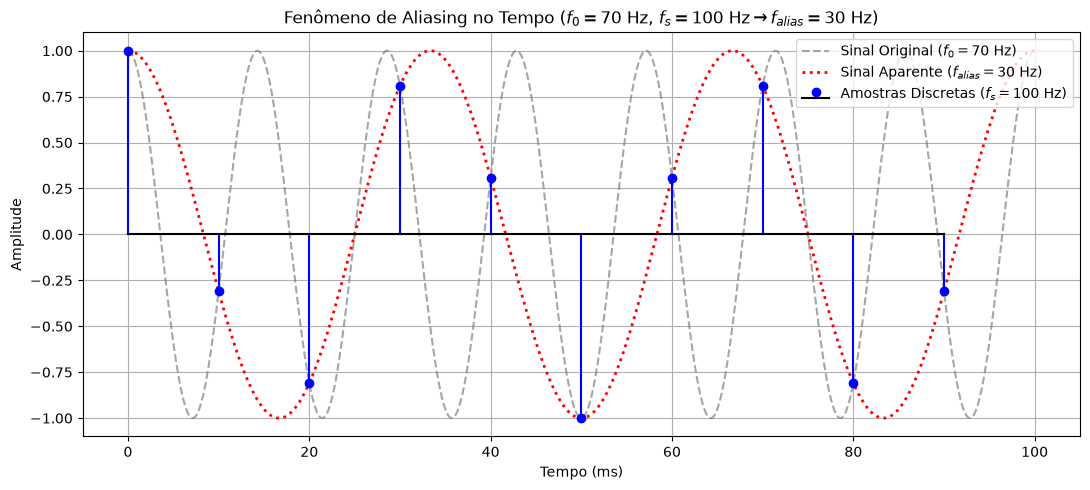

In [2]:
# Parâmetros do experimento
f0 = 70.0    # Frequência real do sinal (Hz)
fs = 100.0   # Frequência de amostragem (Hz)
f_alias = np.abs(f0 - fs)  # Frequência aparente = |70 - 100| = 30 Hz

# Eixo temporal contínuo simulado (100 ms)
t_continua = np.linspace(0, 0.1, 1000)
x_continua_70Hz = np.cos(2 * np.pi * f0 * t_continua)
x_continua_30Hz = np.cos(2 * np.pi * f_alias * t_continua)

# Amostragem discreta a fs = 100 Hz
t_amostras = np.arange(0, 0.1, 1 / fs)
x_amostras = np.cos(2 * np.pi * f0 * t_amostras)

# Plotagem no domínio do tempo
fig1, ax1 = plt.subplots(figsize=(11, 5))

# Sinal original de 70 Hz
ax1.plot(t_continua * 1000, x_continua_70Hz, color='gray', linestyle='--', alpha=0.7, label=r'Sinal Original ($f_0 = 70\text{ Hz}$)')
# Sinal aparente de 30 Hz
ax1.plot(t_continua * 1000, x_continua_30Hz, color='red', linestyle=':', linewidth=2, label=r'Sinal Aparente ($f_{alias} = 30\text{ Hz}$)')
# Amostras discretas tomadas a 100 Hz
ax1.stem(t_amostras * 1000, x_amostras, linefmt='b-', markerfmt='bo', basefmt='k-', label=r'Amostras Discretas ($f_s = 100\text{ Hz}$)')

ax1.set_title(r'Fenômeno de Aliasing no Tempo ($f_0 = 70\text{ Hz}$, $f_s = 100\text{ Hz} \rightarrow f_{alias} = 30\text{ Hz}$)')
ax1.set_xlabel('Tempo (ms)')
ax1.set_ylabel('Amplitude')
ax1.grid(True)
ax1.legend(loc='upper right')

plt.tight_layout()
fig1.savefig("grafico_aliasing_tempo.png")
plt.show()

## 2. Análise Espectral via FFT e Localização do Pico Aparente

Para comprovar analiticamente onde a energia do sinal se posiciona após a amostragem, calculamos a FFT de um registro amostrado com $T_{obs} = 2.0\text{ s}$ ($N = 200$ amostras) sob a mesma taxa $f_s = 100\text{ Hz}$.

A frequência de Nyquist é $f_N = 50\text{ Hz}$. Espera-se que o pico da FFT surja exatamente em $f_{alias} = 30\text{ Hz}$, e não em $70\text{ Hz}$.

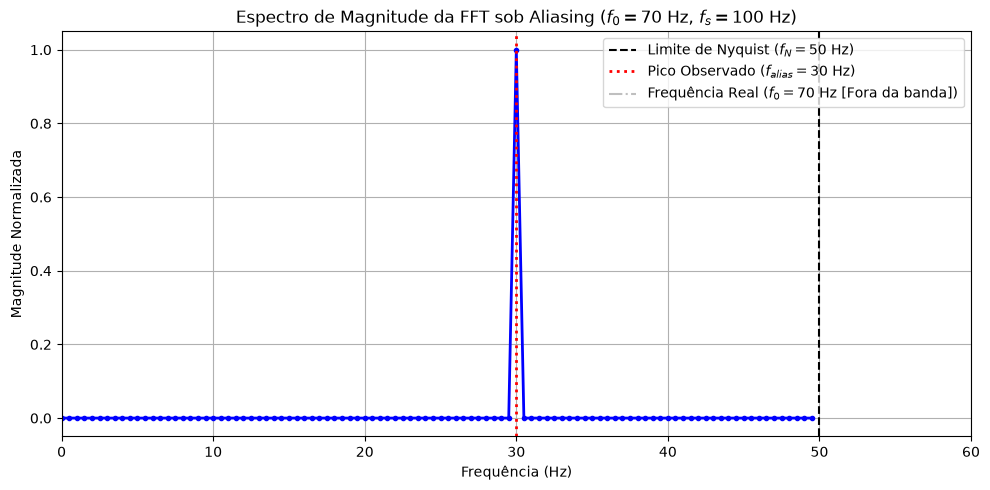

In [3]:
# Registro estendido para alta resolução espectral (2 segundos de observação)
T_obs = 2.0
N_pontos = int(T_obs * fs)
t_ext = np.arange(N_pontos) / fs
x_ext = np.cos(2 * np.pi * f0 * t_ext)

# Cálculo da FFT
X_fft = np.fft.fft(x_ext)
freqs = np.fft.fftfreq(N_pontos, d=1/fs)

# Espectro unilateral positivo (0 até Nyquist)
metade = N_pontos // 2
freqs_pos = freqs[:metade]
magnitude = (2.0 / N_pontos) * np.abs(X_fft[:metade])

f_nyquist = fs / 2.0

# Plotagem do espectro
fig2, ax2 = plt.subplots(figsize=(10, 5))

ax2.plot(freqs_pos, magnitude, 'b-', linewidth=2, marker='o', markersize=3)
ax2.axvline(x=f_nyquist, color='black', linestyle='--', linewidth=1.5, label=r'Limite de Nyquist ($f_N = 50\text{ Hz}$)')
ax2.axvline(x=f_alias, color='red', linestyle=':', linewidth=2, label=r'Pico Observado ($f_{alias} = 30\text{ Hz}$)')
ax2.axvline(x=f0, color='gray', linestyle='-.', alpha=0.5, label=r'Frequência Real ($f_0 = 70\text{ Hz}$ [Fora da banda])')

ax2.set_title(r'Espectro de Magnitude da FFT sob Aliasing ($f_0 = 70\text{ Hz}$, $f_s = 100\text{ Hz}$)')
ax2.set_xlabel('Frequência (Hz)')
ax2.set_ylabel('Magnitude Normalizada')
ax2.set_xlim(0, 60)
ax2.grid(True)
ax2.legend(loc='upper right')

plt.tight_layout()
fig2.savefig("grafico_aliasing_espectro.png")
plt.show()

## 3. Conclusões da Investigação de Aliasing
- **Coincidência Temporal**: As amostras discretas tomadas a $100\text{ Hz}$ de uma senoide de $70\text{ Hz}$ caem exatamente sobre a trajetória de uma senoide de $30\text{ Hz}$, tornando os dois sinais perfeitamente idênticos após a amostragem.
- **Dobra Espectral**: No domínio da frequência, o componente de $70\text{ Hz}$ que excede o limite de Nyquist de $50\text{ Hz}$ é rebatido de volta para a faixa passante discreta $[0, 50\text{ Hz}]$, surgindo na frequência $f_{alias} = 50 - (70 - 50) = 30\text{ Hz}$.
- **Consequências Práticas**: O aliasing corrompe o espectro sem deixar rastros numéricos internos na sequência discreta. Para evitá-lo em aplicações reais (áudio, biomedicina, radares), é indispensável o uso de um **filtro anti-aliasing analógico passa-baixas** antes do conversor A/D.